<a href="https://colab.research.google.com/github/juliooo0/Team_A5/blob/main/Lydia_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing Data from :

https://archive.ics.uci.edu/dataset/2/adult

In [ ]:
# installing package to import data
!pip install ucimlrepo

In [ ]:
# IMPORTING DATA

from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)


{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

# Investigating Data

In [ ]:
# ALL IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [ ]:
ogdf = pd.concat([X, y], axis=1)
display(ogdf.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
ogdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
# TOTAL OBSERVATIONS = 48842
# TOTAL COLUMNS = 15

ogdf.shape

(48842, 15)

In [ ]:
# FINDING NULL VALUES

null_values_per_column = ogdf.isnull().sum()
display(null_values_per_column)

# PROBLEMATIC COLUMNS = 'workclass', 'occupation', 'native-country'

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [ ]:
# FINDING % OF NULL VALUES RELATIVE TO DF

total_observations = ogdf.shape[0]

for column in ['workclass', 'occupation', 'native-country']:
    null_count = null_values_per_column[column]
    percentage_null = (null_count / total_observations) * 100
    print(f"Percentage of null values in '{column}': {percentage_null:.2f}%")


# workclass = 1.97%
# occupation = 1.98%
# native-country = 0.56%

Percentage of null values in 'workclass': 1.97%
Percentage of null values in 'occupation': 1.98%
Percentage of null values in 'native-country': 0.56%


## Cleaning Data

In [ ]:
# Drop rows where 'workclass', 'occupation', or 'native-country' have null values
df_no_na = ogdf.dropna(subset=['workclass', 'occupation', 'native-country'])

# Display the new shape and the number of dropped rows
print(f"Original shape: {ogdf.shape}")
print(f"Cleaned shape: {df_no_na.shape}")
print(f"Number of rows dropped: {len(ogdf) - len(df_no_na)}")

# Preview the cleaned DataFrame
display(df_no_na.tail())

# 1,221 dropped (NaN only); the "?" rows are dropped later in df_q_fix

Original shape: (48842, 15)
Cleaned shape: (47621, 15)
Number of rows dropped: 1221


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48836,33,Private,245211,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,40,United-States,<=50K.
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48841,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


In [ ]:
# Found 4 diff income inputs
# Training set > 50k VS Testing set >50k.

df_no_na['income'].value_counts()

,count
income,
<=50K,24720
<=50K.,11360
>50K,7841
>50K.,3700


consolidating income to 2 diff income values by dropping the period

In [ ]:
df_50k_fix = df_no_na.copy()
df_50k_fix['income'] = df_50k_fix['income'].str.replace('.', '', regex=False)
df_50k_fix['income'].value_counts()

,count
income,
<=50K,36080
>50K,11541


found more Null values that had ? instead

In [ ]:
# values with "?"

(df_50k_fix == '?').sum()

# workclass, occupation, and native country all have ? in data

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


In [ ]:
# changing the ? values into NaN values so that they can be dropped with dropna

df_q_fix = df_50k_fix.replace('?', np.nan).dropna()
(df_q_fix == '?').sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
# checking for white space in names

for col in df_q_fix.select_dtypes(include='object').columns:
    has_space = (df_q_fix[col] != df_q_fix[col].str.strip()).any()
    print(col, has_space)

workclass False
education False
marital-status False
occupation False
relationship False
race False
sex False
native-country False
income False


In [ ]:
#checking for duplicates

df_q_fix.duplicated().sum()

np.int64(47)

In [ ]:
# looking into the 47 flagged duplicates

df_q_fix[df_q_fix.duplicated(keep=False)].sort_values(list(df_q_fix.columns))

# since they are so few, they wont effect data, and could just be crazy coincidences. + the only crazy coincidence part is final weight, and we are dropping that anyway.

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
24667,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36713,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36461,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
48521,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21875,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
7053,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
22494,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K


# Encoding step of cleaning:

## Starting with income <=50 k vs. >50K

## =50k : 0
## >50k : 1

In [ ]:
# code income to be 0 and 1

dfbinaryinc = df_q_fix.copy()
dfbinaryinc['income'] = dfbinaryinc['income'].map({'<=50K': 0, '>50K': 1})
dfbinaryinc['income'].value_counts()

,count
income,
0,34014
1,11208


In [ ]:
# baseline ratio for the clean data set:

baseline = dfbinaryinc['income'].value_counts(normalize=True).max()
print(f'Baseline accuracy: {baseline:.1%}')

Baseline accuracy: 75.2%


baseline accuracy of 75.2% means if the model always predicts <=50k, the model will be right 75% of the time.

Looking at dropping either education or education_num (redundant)

In [ ]:
pd.crosstab(dfbinaryinc['education'], dfbinaryinc['education-num'])

# perfect one to one match bc each row only has one non-zero number

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,1223,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1619,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,577,0,0,0,0,0,0,0,0
1st-4th,0,222,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,449,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,823,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,676,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1507,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,1959,0,0,0,0,0


dropping education and keeping education_num bc it is already in a numeric format

In [ ]:
df_no_catedu = dfbinaryinc.drop(columns=['education']).copy()
df_no_catedu.shape

# lost one feature 15->14

(45222, 14)

Looking at Native Country feature
* has 40 unique values

In [ ]:
df_no_catedu['native-country'].value_counts(normalize=True).round(3)

# 91% of the data is US born, not enough non native to justify making 40 new columns, would make data noisier and cause overfitting

,proportion
native-country,
United-States,0.913
Mexico,0.020
Philippines,0.006
Germany,0.004
Puerto-Rico,0.004
Canada,0.004
El-Salvador,0.003
India,0.003
Cuba,0.003


In [ ]:
# grouping native country into US vs other

df_country = df_no_catedu.copy()
df_country['native-country'] = np.where(df_country['native-country'] == 'United-States', 'United-States', 'Other')
df_country['native-country'].value_counts()

,count
native-country,
United-States,41292
Other,3930


Encoding the other categorical variables

In [ ]:
# looking at the change in column #

text_cols = df_country.select_dtypes(include='object').columns
summary = pd.DataFrame({
    'categories': df_country[text_cols].nunique(),
    'binary_columns_after_drop_first': df_country[text_cols].nunique() - 1
})
print(summary)
print('\nTotal new binary columns:', summary['binary_columns_after_drop_first'].sum())
print('Numeric columns kept:', len(df_country.columns) - len(text_cols))

                categories  binary_columns_after_drop_first
workclass                7                                6
marital-status           7                                6
occupation              14                               13
relationship             6                                5
race                     5                                4
sex                      2                                1
native-country           2                                1

Total new binary columns: 36
Numeric columns kept: 7


In [ ]:
# cleaned and encoded df = encodeddf

encodeddf = pd.get_dummies(df_country, drop_first=True, dtype=int)
encodeddf.shape

(45222, 43)

In [ ]:
# dropping fnlwgt justification - it is just the weight a person holds in the census, no correl with income
# could confuse the model and cause overfitting

encodeddf['fnlwgt'].corr(encodeddf['income'])


np.float64(-0.007263912940611196)

In [ ]:
dfclean = encodeddf.drop(columns=['fnlwgt']).copy()
dfclean.shape

(45222, 42)

# Train / Test Split


In [ ]:

X = dfclean.drop(columns=['income'])
y = dfclean['income']

# split test and train 80/20, stratify so the share of 1s (>50k) is even (24.8 over 50k income)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(36177, 41) (9045, 41)
0.248 0.248


# OUTLIERS

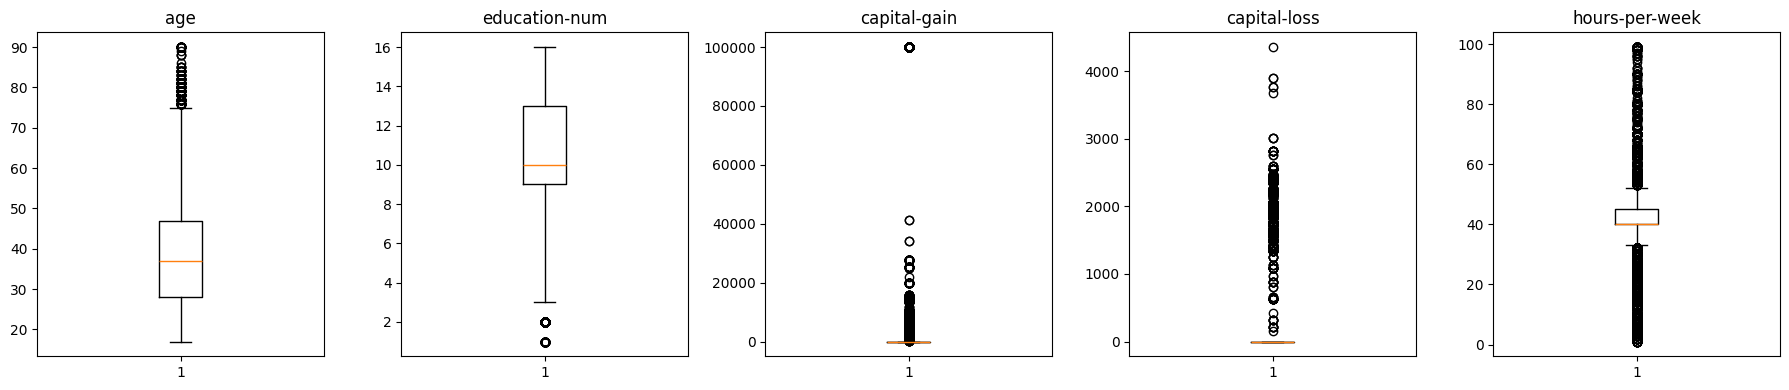

In [ ]:

num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(X_train[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Outlier decisions (based on boxplots of training data):**
- **age:** outliers at 76–90 are real people, so kept
- **education-num:** values 1–2 (Preschool, 1st–4th) are rare but real, so kept
- **capital-gain:** mostly 0, with a cluster at 99,999 that is likely top-coded. Rows kept; log transform tested
- **capital-loss:** mostly 0 with real losses up to ~4,300. Rows kept; log transform tested
- **hours-per-week:** extremes on both ends are real. Capping at the 1st/99th percentile (10–80 hrs) tested

All 4 versions (base, log, cap, cap + log) are compared with 5-fold CV on the training data.

# TESTING OUTLIER APPROACHES
Making 4 different forms of df, with 4 diff treatments of outliers.



In [ ]:
log_cols = ['capital-gain', 'capital-loss']

# cutoffs for capping, from train only
low = X_train['hours-per-week'].quantile(0.01)
high = X_train['hours-per-week'].quantile(0.99)

# 1. base
X_train_base, X_test_base = X_train.copy(), X_test.copy()

# 2. log
X_train_log, X_test_log = X_train.copy(), X_test.copy()
X_train_log[log_cols] = np.log1p(X_train_log[log_cols])
X_test_log[log_cols] = np.log1p(X_test_log[log_cols])

# 3. cap, no log
X_train_cap, X_test_cap = X_train.copy(), X_test.copy()
X_train_cap['hours-per-week'] = X_train_cap['hours-per-week'].clip(low, high)
X_test_cap['hours-per-week'] = X_test_cap['hours-per-week'].clip(low, high)

# 4. cap + log
X_train_caplog, X_test_caplog = X_train_log.copy(), X_test_log.copy()
X_train_caplog['hours-per-week'] = X_train_caplog['hours-per-week'].clip(low, high)
X_test_caplog['hours-per-week'] = X_test_caplog['hours-per-week'].clip(low, high)

print('Cap cutoffs:', low, high)

# Cap cutoffs: 10.0 80.0

versions = {
    'base': (X_train_base, X_test_base),
    'log': (X_train_log, X_test_log),
    'cap': (X_train_cap, X_test_cap),
    'cap + log': (X_train_caplog, X_test_caplog),
}

Cap cutoffs: 10.0 80.0


# LOGIT

In [ ]:
# 5-fold CV setup, shared by every model so comparisons are fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# logit:

def cv_logit(Xtr):
    pipe = Pipeline([
        ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
        ('logit', LogisticRegression(max_iter=1000)),
    ])
    scores = cross_validate(pipe, Xtr, y_train, cv=cv, scoring=['accuracy', 'recall', 'roc_auc'])
    return {
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    }

cv_results = pd.DataFrame(
    [cv_logit(v[0]) for v in versions.values()],
    index=versions.keys()
)
cv_results.round(3)

,accuracy,recall,auc
base,0.848,0.606,0.905
log,0.842,0.594,0.898
cap,0.848,0.607,0.905
cap + log,0.842,0.595,0.898


In [ ]:

pipe = Pipeline([
    ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
    ('logit', LogisticRegression(max_iter=1000)),
])

probs = cross_val_predict(pipe, X_train_base, y_train, cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.30, 0.71, 0.05)
thr_results = pd.DataFrame({
    'threshold': thresholds,
    'accuracy': [accuracy_score(y_train, (probs >= t).astype(int)) for t in thresholds]
})
thr_results.round(3)

,threshold,accuracy
0,0.30,0.825
1,0.35,0.836
2,0.40,0.844
3,0.45,0.849
4,0.50,0.848
5,0.55,0.847
6,0.60,0.845
7,0.65,0.840
8,0.70,0.832


In [ ]:
# checking accuracy across all 5 folds for thresholds 0.45 vs 0.50
# keeping 0.50: 0.45 doesn't win in every fold (loses in fold 3), and its avg gain (~0.1 pt) is smaller than the fold-to-fold variation

rows = []
for i, (_, idx) in enumerate(cv.split(X_train_base, y_train)):
    y_fold = y_train.iloc[idx]
    p_fold = probs[idx]
    rows.append({
        'fold': i + 1,
        'acc_0.45': accuracy_score(y_fold, (p_fold >= 0.45).astype(int)),
        'acc_0.50': accuracy_score(y_fold, (p_fold >= 0.50).astype(int)),
    })

fold_df = pd.DataFrame(rows)
fold_df['diff'] = fold_df['acc_0.45'] - fold_df['acc_0.50']
print(fold_df.round(4))
print('\nStd across folds:')
print(fold_df[['acc_0.45', 'acc_0.50']].std().round(4))

   fold  acc_0.45  acc_0.50    diff
0     1    0.8494    0.8467  0.0026
1     2    0.8494    0.8492  0.0001
2     3    0.8423    0.8449 -0.0026
3     4    0.8509    0.8499  0.0010
4     5    0.8531    0.8511  0.0019

Std across folds:
acc_0.45    0.0040
acc_0.50    0.0025
dtype: float64


In [ ]:
# FINAL TEST:

pipe.fit(X_train_base, y_train)

test_preds = pipe.predict(X_test_base)
test_probs = pipe.predict_proba(X_test_base)[:, 1]

final = pd.DataFrame({
    'accuracy': [accuracy_score(y_test, test_preds)],
    'recall': [recall_score(y_test, test_preds)],
    'auc': [roc_auc_score(y_test, test_probs)],
}, index=['base, threshold 0.5 (test)'])
final['vs_baseline'] = final['accuracy'] - baseline
final.round(3)

,accuracy,recall,auc,vs_baseline
"base, threshold 0.5 (test)",0.844,0.589,0.901,0.092


## KNN

In [ ]:
# KNN: trying different k values with 5-fold CV on the training data

results = []

for k in tqdm(range(1, 52, 5)):
    pipe_knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_validate(pipe_knn, X_train_base, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
    results.append({
        'k': k,
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    })

knn_results_df = pd.DataFrame(results)
knn_results_df.round(3)

100%|██████████| 11/11 [03:42<00:00, 20.23s/it]


,k,accuracy,recall,auc
0,1,0.798,0.584,0.726
1,6,0.829,0.505,0.854
2,11,0.833,0.587,0.872
3,16,0.835,0.550,0.878
4,21,0.835,0.579,0.880
5,26,0.835,0.558,0.881
6,31,0.834,0.575,0.882
7,36,0.834,0.559,0.882
8,41,0.834,0.574,0.882
9,46,0.834,0.561,0.882


Max CV accuracy = 0.835 | Best k = 26


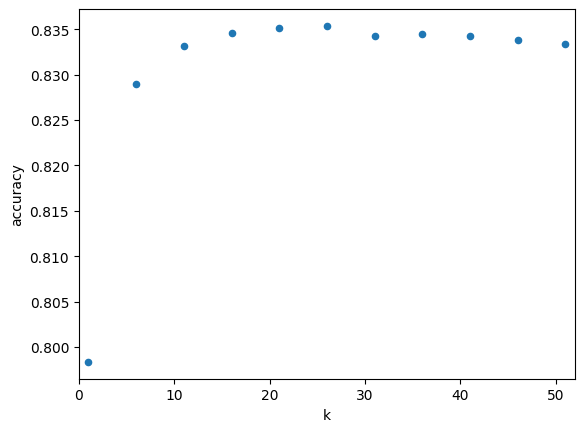

In [ ]:
# Plot CV accuracy against k, and find the best k
knn_results_df.plot.scatter(x='k', y='accuracy', xlim=[0, 52]);

best_row = knn_results_df['accuracy'].idxmax()
print('Max CV accuracy =', round(knn_results_df.loc[best_row, 'accuracy'], 3),
      '| Best k =', knn_results_df.loc[best_row, 'k'])

Logit still is a better test bc of higher accuracy

testing k=21 with the 4 diff outlier cases to see if this improves accuracy


In [ ]:
# KNN (k=21): comparing the 4 outlier versions with 5-fold CV on training data

results = []
for name, (Xtr, Xte) in tqdm(versions.items()):
    pipe_knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=21)),
    ])
    scores = cross_validate(pipe_knn, Xtr, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
    results.append({
        'version': name,
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    })

knn_versions_df = pd.DataFrame(results).set_index('version')
knn_versions_df.round(3)

100%|██████████| 4/4 [01:16<00:00, 19.11s/it]


,accuracy,recall,auc
version,,,
base,0.835,0.579,0.880
log,0.836,0.601,0.884
cap,0.834,0.578,0.880
cap + log,0.836,0.599,0.884


**KNN results**

- picked k = 21 because accuracy flattens out after k = 16 (~83.5%), and an odd k avoids ties. even k's had lower recall bc ties go to 0
- tested the 4 outlier versions at k = 21:
  - log helped a little: recall went from 0.579 → 0.601 and auc from 0.880 → 0.884, accuracy basically the same
  - capping hours didn't change anything
- going with the **log** version for knn
- this is the opposite of logit, where log made it slightly worse. makes sense bc knn uses distances, and the huge capital-gain values were stretching them out. logging shrinks those gaps
- knn is still behind logit (83.6% vs 84.8% cv accuracy)

## NAIVE BAYES

In [ ]:
# Naive Bayes: comparing Multinomial (class lab) vs Gaussian, across the 4 outlier versions
# no scaling: NB doesn't need it, and scaling creates negatives that break MultinomialNB

results = []
for name, (Xtr, Xte) in tqdm(versions.items()):
    for nb_name, nb in [('Multinomial', MultinomialNB()), ('Gaussian', GaussianNB())]:
        scores = cross_validate(nb, Xtr, y_train, cv=cv,
                                scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
        results.append({
            'nb_type': nb_name,
            'version': name,
            'accuracy': scores['test_accuracy'].mean(),
            'recall': scores['test_recall'].mean(),
            'auc': scores['test_roc_auc'].mean(),
        })

nb_results_df = pd.DataFrame(results).set_index(['nb_type', 'version'])
nb_results_df.round(3)

100%|██████████| 4/4 [00:02<00:00,  1.36it/s]


,,accuracy,recall,auc
nb_type,version,,,
Multinomial,base,0.774,0.213,0.402
Gaussian,base,0.823,0.732,0.887
Multinomial,log,0.781,0.360,0.847
Gaussian,log,0.728,0.868,0.857
Multinomial,cap,0.774,0.213,0.402
Gaussian,cap,0.823,0.733,0.887
Multinomial,cap + log,0.781,0.360,0.847
Gaussian,cap + log,0.728,0.869,0.857


**Naive Bayes results**

- the class lab used multinomial NB, which is made for word counts. my data is 0/1 columns + numbers like age and hours, so i tested both multinomial and gaussian (the version made for numeric columns) on all 4 outlier versions

- no scaling bc NB doesn't need it, and scaling makes negative values which break multinomial

- **multinomial was bad:** base accuracy was 77.4% (barely above the 75.2% baseline) and auc was 0.402 (worse than a coin flip). it treats the huge capital-gain numbers as "counts" so they drown out everything else. log helped (auc 0.847) but still weak

- **gaussian on base was the best NB:** 82.3% accuracy, auc 0.887, and recall 0.732, the highest recall of any model so far

- **gaussian on log backfired:** accuracy dropped to 72.8% (below baseline). logging turns capital-gain into 2 clumps (lots of 0s and a group around 8–11), which breaks gaussian's bell-curve assumption, so it over-predicts >50k

- capping didn't change anything again

- going with **gaussian NB, base version**

- NB assumes columns are independent, but mine overlap (like relationship and marital-status), which is probably why it's below logit. in the spam lab NB did great bc the 7,000 word columns weren't very correlated

- logit still wins on accuracy (84.8% vs 82.3%), but NB would be the pick if catching high earners mattered more

## DECISION TREE

In [ ]:
# full tree (no limits)
full_clf = DecisionTreeClassifier(random_state=0)
full_clf.fit(X_train_base, y_train)

print('Number of nodes:', full_clf.tree_.node_count)
print('Train accuracy:', round(accuracy_score(y_train, full_clf.predict(X_train_base)), 3))

full_cv = cross_validate(full_clf, X_train_base, y_train, cv=cv, scoring='accuracy')
print('CV accuracy:', round(full_cv['test_score'].mean(), 3))

# train accuracy vs CV accuracy shows overfitting:

# train accuracy vs CV accuracy shows overfitting:
# Number of nodes: 13211
# Train accuracy: 0.972
# CV accuracy: 0.813

In [ ]:
# grid search over tree settings, scored with the same 5-fold CV as the other models
param_grid = {
    'max_depth': [5, 8, 10, 15, 20],
    'min_samples_leaf': [10, 20, 50, 100],
    'min_impurity_decrease': [0, 0.0005, 0.001],
}

gridSearch = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid,
                          cv=cv, scoring='accuracy', n_jobs=-1)
gridSearch.fit(X_train_base, y_train)

print('Best CV accuracy:', round(gridSearch.best_score_, 3))
print('Best parameters:', gridSearch.best_params_)

# recall + auc for the best tree, to add to the scoreboard
best_cv = cross_validate(gridSearch.best_estimator_, X_train_base, y_train, cv=cv,
                         scoring=['accuracy', 'recall', 'roc_auc'])
print('Recall:', round(best_cv['test_recall'].mean(), 3),
      '| AUC:', round(best_cv['test_roc_auc'].mean(), 3))

# Best CV accuracy: 0.854
# Best parameters: {'max_depth': 10, 'min_impurity_decrease': 0, 'min_samples_leaf': 10}
# Recall: 0.583 | AUC: 0.901

Best CV accuracy: 0.854
Best parameters: {'max_depth': 10, 'min_impurity_decrease': 0, 'min_samples_leaf': 10}
Recall: 0.583 | AUC: 0.901


**Decision tree results**

- followed the class lab: built a full tree first, then used grid search to find the best settings

- only used the base version bc trees don't need scaling, and logging a column doesn't change where the tree splits

- **full tree (no limits):** 13,211 nodes, 97.2% train accuracy but only 81.3% cv accuracy. that big gap = overfitting, the tree memorized the training data

- **grid search** tested max_depth, min_samples_leaf, and min_impurity_decrease with the same 5-fold cv as the other models

- **best tree:** max_depth = 10, min_samples_leaf = 10, min_impurity_decrease = 0

- cv accuracy 85.4%, recall 0.583, auc 0.901

- limiting the tree fixed the overfitting and raised accuracy from 81.3% to 85.4%

- **best model on accuracy so far:** 85.4% vs logit's 84.8%. the gap is small (under 1 pt), so the tree is only slightly better

- leaf size 10 was the smallest value tested, so a smaller value (like 5) might do even better. worth testing later

## RANDOM FOREST

In [ ]:
# random forest: 500 trees, scored with the same 5-fold CV as the other models
rf = RandomForestClassifier(n_estimators=500, random_state=0, criterion='gini', n_jobs=-1)

rf_cv = cross_validate(rf, X_train_base, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'roc_auc'])
print('CV accuracy:', round(rf_cv['test_accuracy'].mean(), 3),
      '| Recall:', round(rf_cv['test_recall'].mean(), 3),
      '| AUC:', round(rf_cv['test_roc_auc'].mean(), 3))

CV accuracy: 0.845 | Recall: 0.62 | AUC: 0.894


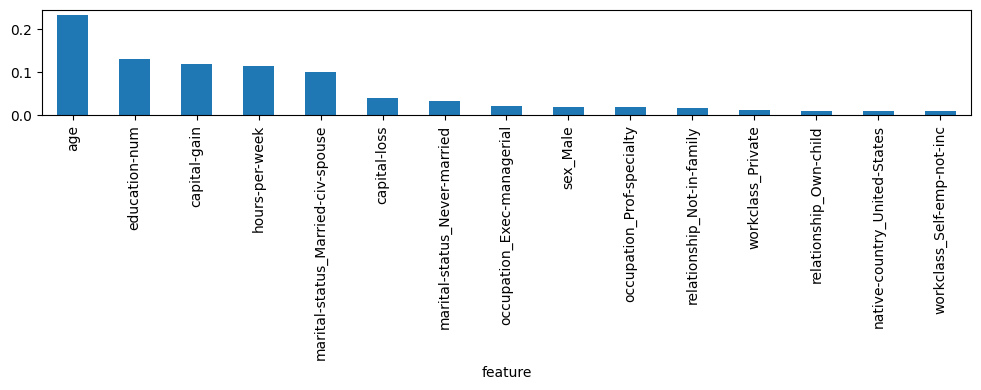

In [ ]:
# which features the forest relied on most
rf.fit(X_train_base, y_train)
importance_df = pd.DataFrame({'feature': X_train_base.columns, 'importance': rf.feature_importances_})
importance_df = importance_df.sort_values('importance', ascending=False).head(15)

importance_df.plot(kind='bar', x='feature', legend=False, figsize=(10, 4))
plt.tight_layout()
plt.show()

In [ ]:
# grid search for random forest, same 5-fold CV as the other models
rf_grid = {
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 0.5],
}

rf_search = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                         rf_grid, cv=cv, scoring='accuracy', verbose=1)
rf_search.fit(X_train_base, y_train)

print('Best CV accuracy:', round(rf_search.best_score_, 3))
print('Best parameters:', rf_search.best_params_)

best_rf_cv = cross_validate(rf_search.best_estimator_, X_train_base, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'])
print('Recall:', round(best_rf_cv['test_recall'].mean(), 3),
      '| AUC:', round(best_rf_cv['test_roc_auc'].mean(), 3))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best CV accuracy: 0.862
Best parameters: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 5}
Recall: 0.618 | AUC: 0.916
